# Knowledge Distillation

**Idea:** a big model (teacher) helps train a small model (student) by sharing its soft predictions.


In [2]:
import os, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Fix the random seed so results are repeatable(you can randomise the seed if you want)
torch.manual_seed(42)
np.random.seed(42)

from google.colab import drive
drive.mount("/content/drive")
os.chdir("/content/drive/MyDrive")  # data/ and outputs/ will now be created here
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

print("PyTorch version:", torch.__version__)

Mounted at /content/drive
PyTorch version: 2.11.0+cpu


In [3]:
# Fashion-MNIST: 28x28 grayscale pictures of clothes, 10 classes
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.286,), (0.353,))])
full_train = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
test_data = datasets.FashionMNIST("data", train=False, download=True, transform=transform)

# Shuffle once, then use 12,000 images for training and 3,000 for validation
idx = np.random.permutation(len(full_train))
train_data = Subset(full_train, idx[:12000].tolist())
val_data = Subset(full_train, idx[12000:15000].tolist())

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
val_loader = DataLoader(val_data, batch_size=64)
test_loader = DataLoader(test_data, batch_size=64)
print("train / val / test sizes:", len(train_data), len(val_data), len(test_data))

train / val / test sizes: 12000 3000 10000


In [4]:
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, loader):
    """Return (average loss, accuracy) of the model on a dataset."""
    model.eval()
    correct, total, loss_sum = 0, 0, 0.0
    with torch.no_grad():
        for x, y in loader:
            out = model(x)
            loss_sum += loss_fn(out, y).item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total

def train(model, loader, epochs=3, lr=1e-3, weight_decay=0.0, make_scheduler=None):
    """Train with Adam. Returns a table of per-epoch results and the training time."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = make_scheduler(optimizer) if make_scheduler else None
    history = []
    start = time.time()
    for epoch in range(epochs):
        model.train()
        loss_sum, seen = 0.0, 0
        for x, y in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            seen += len(y)
        val_loss, val_acc = evaluate(model, val_loader)
        history.append({"epoch": epoch + 1, "train_loss": loss_sum / seen, "val_loss": val_loss,
                        "val_acc": val_acc, "lr": optimizer.param_groups[0]["lr"]})
        print(f"epoch {epoch+1}/{epochs}  train_loss={loss_sum/seen:.4f}  val_loss={val_loss:.4f}  val_acc={val_acc:.4f}")
        if scheduler:
            scheduler.step()
    return pd.DataFrame(history), time.time() - start

In [5]:
# One-hidden-layer network; "hidden" controls how big it is
class Net(nn.Module):
    def __init__(self, hidden):
        super().__init__()
        self.layers = nn.Sequential(nn.Flatten(), nn.Linear(784, hidden), nn.ReLU(), nn.Linear(hidden, 10))

    def forward(self, x):
        return self.layers(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

## Step 1: Train a big teacher and a small student (normally)

In [6]:
teacher = Net(hidden=512)
teacher_hist, teacher_time = train(teacher, train_loader)

student_plain = Net(hidden=32)
plain_hist, plain_time = train(student_plain, train_loader)

epoch 1/3  train_loss=0.5996  val_loss=0.4685  val_acc=0.8347
epoch 2/3  train_loss=0.4194  val_loss=0.4383  val_acc=0.8527
epoch 3/3  train_loss=0.3736  val_loss=0.4300  val_acc=0.8410
epoch 1/3  train_loss=0.7362  val_loss=0.5459  val_acc=0.7930
epoch 2/3  train_loss=0.4907  val_loss=0.4612  val_acc=0.8367
epoch 3/3  train_loss=0.4464  val_loss=0.4424  val_acc=0.8440


## Step 2: Train a small student using the teacher

The student's loss has two parts: the normal loss on the true labels, and a loss that makes it copy the teacher's softened probabilities. `T` is the temperature (higher = softer) and `alpha` is how much weight the teacher part gets.

In [7]:
teacher.eval()
student_distilled = Net(hidden=32)
optimizer = torch.optim.Adam(student_distilled.parameters(), lr=1e-3)
T = 3.0
alpha = 0.5

start = time.time()
for epoch in range(3):
    student_distilled.train()
    for x, y in train_loader:
        with torch.no_grad():
            teacher_out = teacher(x)
        student_out = student_distilled(x)

        hard_loss = loss_fn(student_out, y)  # match the true labels
        soft_loss = nn.functional.kl_div(     # match the teacher
            nn.functional.log_softmax(student_out / T, dim=1),
            nn.functional.softmax(teacher_out / T, dim=1),
            reduction="batchmean") * T * T
        loss = alpha * soft_loss + (1 - alpha) * hard_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    val_loss, val_acc = evaluate(student_distilled, val_loader)
    print(f"epoch {epoch+1}/3  val_acc={val_acc:.4f}")
distilled_time = time.time() - start

epoch 1/3  val_acc=0.8070
epoch 2/3  val_acc=0.8187
epoch 3/3  val_acc=0.8383


## Step 3: Compare on the test set

               model  test_accuracy  test_loss  parameters  training_seconds
0            teacher         0.8312   0.463105      407050         15.395667
1      student_plain         0.8291   0.478766       25450         11.914289
2  student_distilled         0.8261   0.487418       25450         13.566169


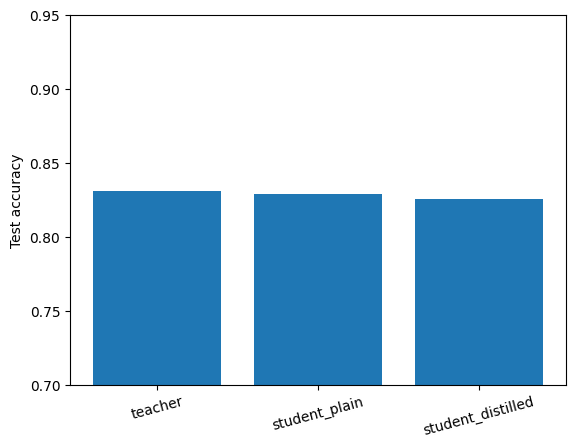

In [9]:
rows = []
for name, model, secs in [("teacher", teacher, teacher_time),
                          ("student_plain", student_plain, plain_time),
                          ("student_distilled", student_distilled, distilled_time)]:
    test_loss, test_acc = evaluate(model, test_loader)
    rows.append({"model": name, "test_accuracy": test_acc, "test_loss": test_loss,
                 "parameters": count_params(model), "training_seconds": secs})

results = pd.DataFrame(rows)
results.to_csv("outputs/distillation_results.csv", index=False)
print(results)

plt.bar(results["model"], results["test_accuracy"])
plt.ylabel("Test accuracy")
plt.ylim(0.7, 0.95)  # zoomed in so small differences are visible
plt.xticks(rotation=15)
plt.savefig("outputs/distillation_accuracy_comparison.png")
plt.show()